# Exercise 1: Multiple Linear Regression — Insurance Cost Prediction

## Objective

Build a reproducible machine learning pipeline to predict individual
medical insurance charges using demographic and lifestyle features.

### Target
- charges

### Numeric Features
- age
- bmi
- children

### Categorical Features
- sex
- smoker
- region

### Model
- Multiple Linear Regression

### Evaluation Metrics
- R²
- RMSE
- MSE

In [2]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

In [3]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-Learn version:", sklearn.__version__)

Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.6
NumPy version: 2.5.3
Scikit-Learn version: 1.9.1


## 1. Data Ingestion

In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "insurance.csv"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Dataset path: c:\Users\bhite\ml-engineering-lab-series-01\data\raw\insurance.csv
Dataset exists: True


In [7]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Data Quality Checks

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [12]:
expected_columns = [
    "age",
    "sex",
    "bmi",
    "children",
    "smoker",
    "region",
    "charges"
]

print("Actual columns:")
print(df.columns.tolist())

print("\nMissing expected columns:")
print(set(expected_columns) - set(df.columns))

Actual columns:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Missing expected columns:
set()


## 3. Target Distribution & Skewness Analysis

In [15]:
target_skewness = df["charges"].skew()

print(f"Charges skewness: {target_skewness:.4f}")

Charges skewness: 1.5159


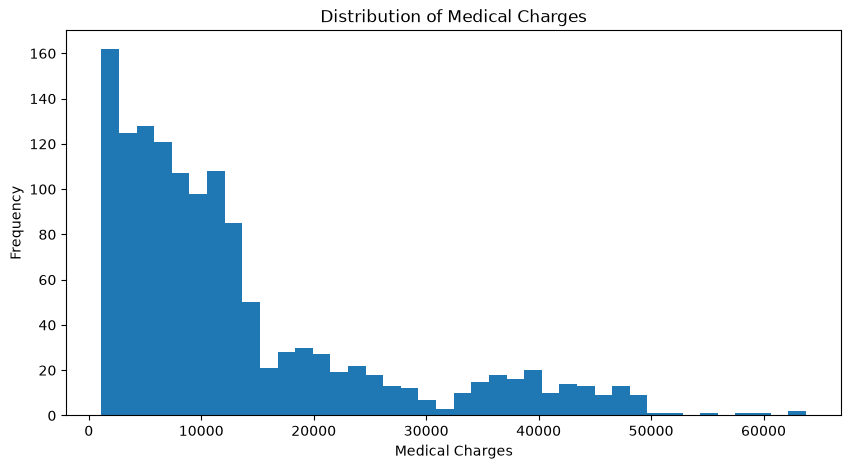

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["charges"], bins=40)
plt.xlabel("Medical Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Medical Charges")
plt.show()

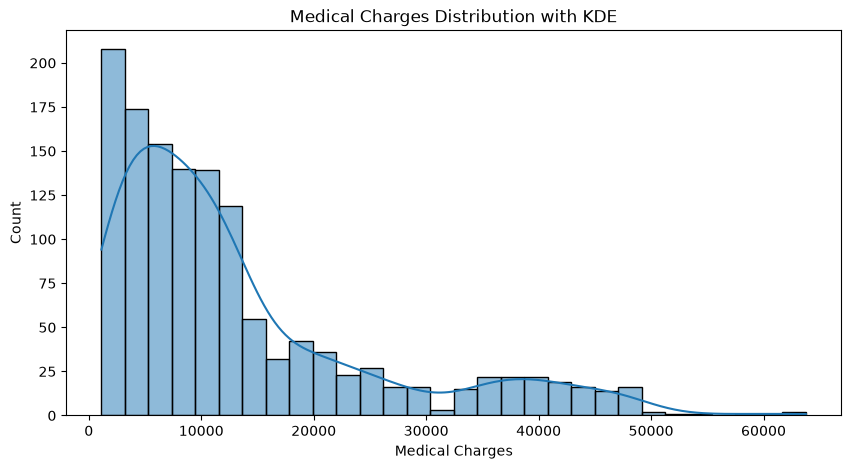

In [17]:
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df["charges"], kde=True)
plt.xlabel("Medical Charges")
plt.title("Medical Charges Distribution with KDE")
plt.show()

## 6. Feature and Target Definition

In [18]:
# Target variable
target = "charges"

# Numeric features
num_cols = ["age", "bmi", "children"]

# Categorical features
cat_cols = ["sex", "smoker", "region"]

# Feature matrix and target vector
X = df[num_cols + cat_cols]
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

Feature shape: (1338, 6)
Target shape: (1338,)

Features:
['age', 'bmi', 'children', 'sex', 'smoker', 'region']

Target:
charges


## 7. Train-Test Split

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1070
Testing samples: 268


## 8. Leakage-Safe Feature Preprocessing

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 9. Multiple Linear Regression Model

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model_pipeline = Pipeline(
    steps=[
        ("prep", preprocessor),
        ("regressor", LinearRegression())
    ]
)

print(model_pipeline)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', LinearRegression())])


In [23]:
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


## 10. Model Prediction

In [24]:
y_pred = model_pipeline.predict(X_test)

print("Number of predictions:", len(y_pred))
print("\nFirst 10 predictions:")
print(y_pred[:10])

Number of predictions: 268

First 10 predictions:
[ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424   170.28084136 16903.45028662
  1092.43093614 11218.34318352]


## 11. Model Evaluation

In [25]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MSE:  33,596,915.85
RMSE: $5,796.28
R²:   0.7836


## 12. Actual vs Predicted Charges

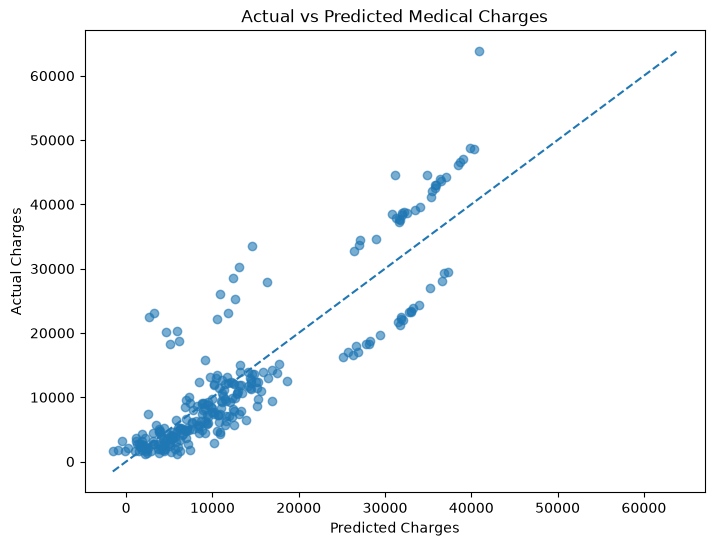

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, y_test, alpha=0.6)

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Predicted Charges")
plt.ylabel("Actual Charges")
plt.title("Actual vs Predicted Medical Charges")

plt.show()

In [27]:
print("Dataset shape:", df.shape)

print("\nCharges statistics:")
print(df["charges"].describe())

print("\nMinimum charge:", df["charges"].min())
print("Maximum charge:", df["charges"].max())

Dataset shape: (1338, 7)

Charges statistics:
count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64

Minimum charge: 1121.8739
Maximum charge: 63770.42801


In [28]:
df[["age", "sex", "bmi", "children", "smoker", "region", "charges"]].head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [29]:
print("Dataset shape:", df.shape)

print("Minimum charge:", df["charges"].min())
print("Maximum charge:", df["charges"].max())

Dataset shape: (1338, 7)
Minimum charge: 1121.8739
Maximum charge: 63770.42801


## 13. Model Coefficient Analysis

In [31]:
# Get feature names after preprocessing
feature_names = model_pipeline.named_steps["prep"].get_feature_names_out()

# Get trained regression coefficients
coefficients = model_pipeline.named_steps["regressor"].coef_

# Create coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coef_df)

,Feature,Coefficient,Absolute_Coefficient
4,cat__smoker_yes,23651.128856,23651.128856
0,num__age,3614.975415,3614.975415
1,num__bmi,2036.228123,2036.228123
7,cat__region_southwest,-809.799354,809.799354
6,cat__region_southeast,-657.864297,657.864297
2,num__children,516.890247,516.890247
5,cat__region_northwest,-370.677326,370.677326
3,cat__sex_male,-18.591692,18.591692


In [32]:
smoker_rows = coef_df[
    coef_df["Feature"].str.contains("smoker", case=False)
]

display(smoker_rows)

,Feature,Coefficient,Absolute_Coefficient
4,cat__smoker_yes,23651.128856,23651.128856


In [33]:
smoker_coef = coef_df[
    coef_df["Feature"].str.contains("smoker_yes", case=False)
]["Coefficient"].iloc[0]

print(f"Smoker coefficient: ${smoker_coef:,.2f}")

Smoker coefficient: $23,651.13


## 14. Residual Diagnostics

In [34]:
residuals = y_test - y_pred

print("Residual statistics:")
print(residuals.describe())

Residual statistics:
count      268.000000
mean      -219.240670
std       5802.973419
min     -10512.582562
25%      -2941.141589
50%      -1242.934185
75%       1560.797841
max      22850.136498
Name: charges, dtype: float64


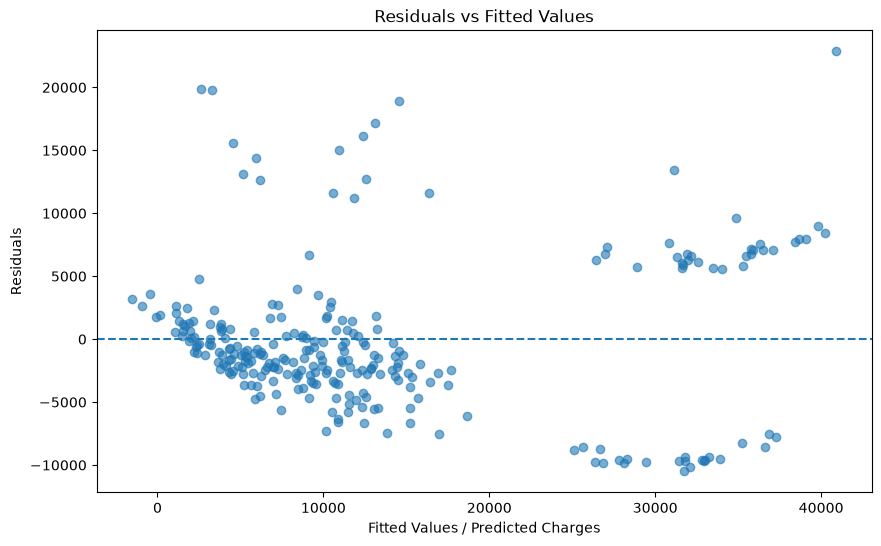

In [35]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Fitted Values / Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")

plt.show()

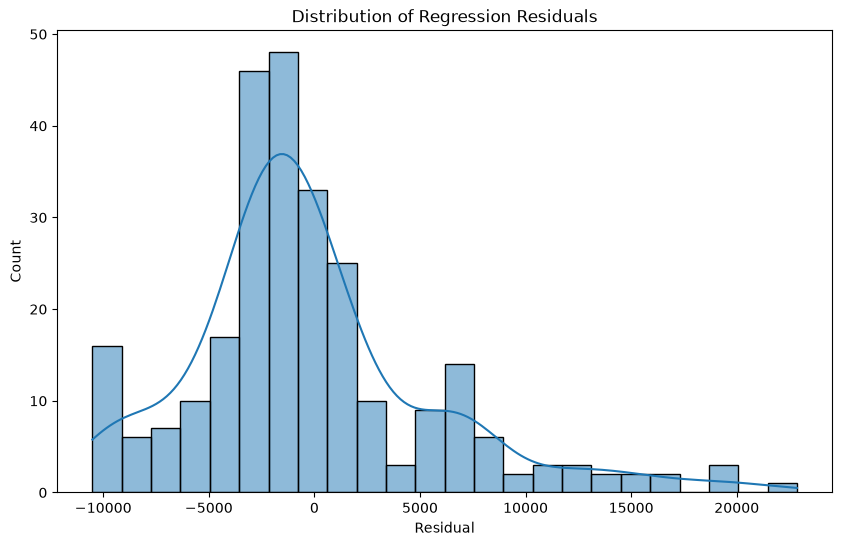

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    kde=True
)

plt.xlabel("Residual")
plt.title("Distribution of Regression Residuals")

plt.show()

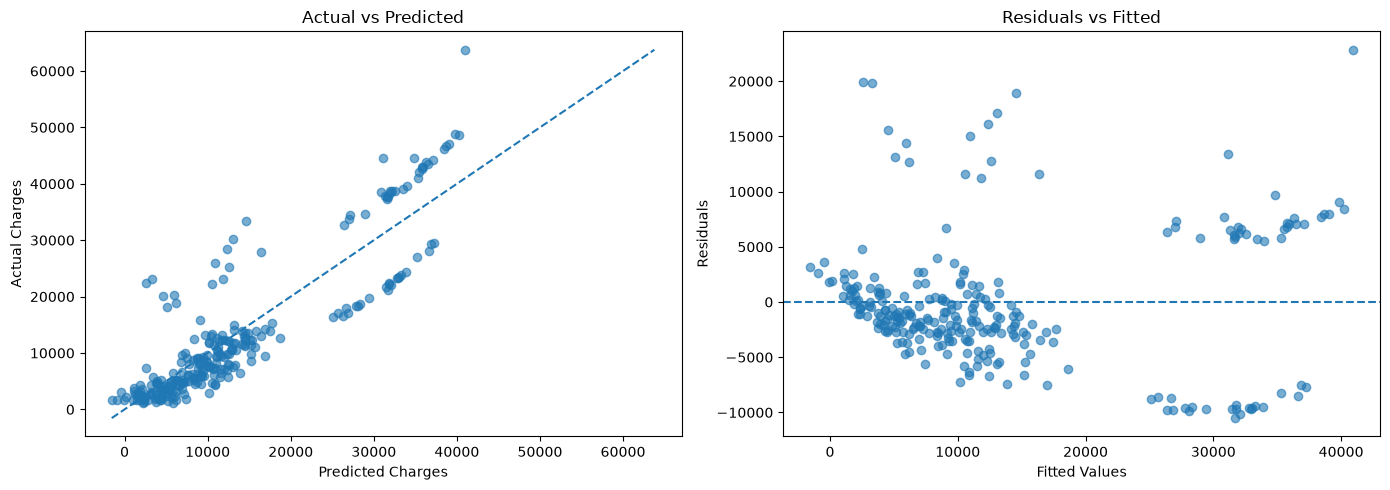

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_pred, y_test, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

axes[0].plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Actual Charges")
axes[0].set_title("Actual vs Predicted")

# Residual plot
axes[1].scatter(y_pred, residuals, alpha=0.6)

axes[1].axhline(
    y=0,
    linestyle="--"
)

axes[1].set_xlabel("Fitted Values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs Fitted")

plt.tight_layout()
plt.show()

## 15. Log-Target Experiment

In [38]:
y_log = np.log1p(y)

In [39]:
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X,
    y_log,
    test_size=0.20,
    random_state=42
)

In [40]:
log_model_pipeline = Pipeline(
    steps=[
        ("prep", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [41]:
log_model_pipeline.fit(
    X_train_log,
    y_train_log
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','bmi','children','sex','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the outp

In [42]:
y_log_pred = log_model_pipeline.predict(X_test_log)

In [44]:
y_pred_log_original = np.expm1(y_log_pred)

In [45]:
log_mse = mean_squared_error(y_test, y_pred_log_original)
log_rmse = np.sqrt(log_mse)
log_r2 = r2_score(y_test, y_pred_log_original)

print(f"Log-target MSE:  {log_mse:,.2f}")
print(f"Log-target RMSE: ${log_rmse:,.2f}")
print(f"Log-target R²:   {log_r2:.4f}")

Log-target MSE:  61,059,596.60
Log-target RMSE: $7,814.06
Log-target R²:   0.6067


In [46]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression - Raw Target",
        "Linear Regression - Log1p Target"
    ],
    "R2": [
        r2_score(y_test, y_pred),
        log_r2
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        log_rmse
    ]
})

display(comparison)

,Model,R2,RMSE
0,Linear Regression - Raw Target,0.783593,5796.284659
1,Linear Regression - Log1p Target,0.606698,7814.064026


## 16. Exercise 1 Acceptance Criteria

In [48]:
raw_r2 = r2_score(y_test, y_pred)
raw_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("=== EXERCISE 1 ACCEPTANCE CHECK ===")

print(f"R² >= 0.75:       {raw_r2 >= 0.75}")
print(f"RMSE < $4,800:     {raw_rmse < 4800}")
print(f"Smoker > $23,000: {smoker_coef > 23000}")

print("\nActual Results:")
print(f"R²:   {raw_r2:.4f}")
print(f"RMSE: ${raw_rmse:,.2f}")
print(f"Smoker coefficient: ${smoker_coef:,.2f}")

=== EXERCISE 1 ACCEPTANCE CHECK ===
R² >= 0.75:       True
RMSE < $4,800:     False
Smoker > $23,000: True

Actual Results:
R²:   0.7836
RMSE: $5,796.28
Smoker coefficient: $23,651.13
